In [100]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

# Create project folder
os.makedirs("/content/ai-ml-final-project/analytics", exist_ok=True)

# Load dataset
df = sns.load_dataset("titanic")

# Save dataset
df.to_csv(
    "/content/ai-ml-final-project/analytics/titanic.csv",
    index=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (891, 15)


In [101]:
df["survived"].value_counts()

,count
survived,
0,549
1,342


In [102]:
df["survived"].value_counts(normalize=True) * 100

,proportion
survived,
0,61.616162
1,38.383838


Stratified Train-Test Split

In [103]:
X = df.drop("survived", axis=1)
y = df["survived"]

In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Verify the Split

In [105]:
print("Training Set:", X_train.shape)
print("Testing Set :", X_test.shape)

Training Set: (712, 14)
Testing Set : (179, 14)


In [106]:
print(y_train.value_counts(normalize=True))
print()

print(y_test.value_counts(normalize=True))

survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


#Preprocessing Pipeline
Identify numeric and categorical columns

In [107]:
numeric_features = [
    "age",
    "fare",
    "sibsp",
    "parch",
    "pclass"
]

categorical_features = [
    "sex",
    "embarked"
]

print("Numeric Features :", numeric_features)
print("Categorical Features :", categorical_features)

Numeric Features : ['age', 'fare', 'sibsp', 'parch', 'pclass']
Categorical Features : ['sex', 'embarked']


Numeric preprocessing

In [108]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

Categorical preprocessing

In [109]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

Combine both using ColumnTransformer

In [110]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Import the models and evaluation metrics

In [111]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

Create the Logistic Regression Pipeline

In [112]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(random_state=42))
    ]
)

Train the Logistic Regression model

In [113]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare', 'sibsp',
                                                   'parch', 'pclass']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'embarked'])])),
                ('classifier', LogisticRegression(random_state=42))])

Make predictions

In [114]:
y_pred_logistic = logistic_model.predict(X_test)

Evaluate the model

In [115]:
print("Accuracy :", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic))
print("Recall   :", recall_score(y_test, y_pred_logistic))
print("F1 Score :", f1_score(y_test, y_pred_logistic))

Accuracy : 0.8044692737430168
Precision: 0.7931034482758621
Recall   : 0.6666666666666666
F1 Score : 0.7244094488188977


Confusion Matrix

In [116]:
print(confusion_matrix(y_test, y_pred_logistic))

[[98 12]
 [23 46]]


Classification Report

In [117]:
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



#Decision Tree Model
Create Pipeline

In [118]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]
)

Train Model

In [119]:
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare', 'sibsp',
                                                   'parch', 'pclass']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'embarked'])])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

Predict

In [120]:
y_pred_tree = decision_tree_model.predict(X_test)

Evaluate

In [121]:
print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall   :", recall_score(y_test, y_pred_tree))
print("F1 Score :", f1_score(y_test, y_pred_tree))

Accuracy : 0.8156424581005587
Precision: 0.7727272727272727
Recall   : 0.7391304347826086
F1 Score : 0.7555555555555555


Confusion Matrix

In [122]:
print(confusion_matrix(y_test, y_pred_tree))

[[95 15]
 [18 51]]


Classification Report

In [123]:
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85       110
           1       0.77      0.74      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



#Random Forest
Create Pipeline

In [124]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(random_state=42))
    ]
)

Train

In [125]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare', 'sibsp',
                                                   'parch', 'pclass']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'embarked'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

Predict

In [126]:
y_pred_rf = random_forest_model.predict(X_test)

Evaluate

In [127]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

Accuracy : 0.8156424581005587
Precision: 0.8
Recall   : 0.6956521739130435
F1 Score : 0.7441860465116279


Confusion Matrix

In [128]:
print(confusion_matrix(y_test, y_pred_rf))

[[98 12]
 [21 48]]


Classification Report

In [129]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



#Create a Comparison DataFrame

In [130]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
    roc_auc_score(y_test, y_prob_logistic),
    roc_auc_score(y_test, y_prob_tree),
    roc_auc_score(y_test, y_prob_rf)
]
})

comparison = comparison.round(4)

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437
1,Decision Tree,0.8156,0.7727,0.7391,0.7556,0.7967
2,Random Forest,0.8156,0.8000,0.6957,0.7442,0.8271


In [131]:
# ROC-AUC Evaluation

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_logistic), 4))

print("Decision Tree ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_tree), 4))

print("Random Forest ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_rf), 4))

Logistic Regression ROC-AUC: 0.8437
Decision Tree ROC-AUC: 0.7967
Random Forest ROC-AUC: 0.8271


#Model Comparison Summary

Three machine learning models were trained and evaluated on the Titanic dataset:
1. Logistic Regression
2. Decision Tree
3. Random Forest

Decision Tree and Random Forest achieved the highest accuracy (81.56%).
Among them, the Decision Tree obtained the highest Recall (73.91%) and F1 Score (75.56%), indicating a better balance between correctly identifying survivors and minimizing classification errors.

Therefore, the Decision Tree model was selected as the best-performing model for this dataset.

In [132]:
param_grid = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)

Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}
Best Cross-Validation F1 Score: 0.7507977100362971


In [133]:
best_tree_model = grid_search.best_estimator_

y_pred_tuned = best_tree_model.predict(X_test)

print("Tuned Decision Tree Results")
print("----------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned Decision Tree Results
----------------------------
Accuracy: 0.7932960893854749
Precision: 0.7580645161290323
Recall: 0.6811594202898551
F1 Score: 0.7175572519083969

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.86      0.84       110
           1       0.76      0.68      0.72        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179

Confusion Matrix:
[[95 15]
 [22 47]]


In [134]:
tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Decision Tree",
        "Tuned Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "Precision": [
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_tuned)
    ],
    "Recall": [
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_tuned)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_tuned)
    ]
})

tuning_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Original Decision Tree,0.8156,0.7727,0.7391,0.7556
1,Tuned Decision Tree,0.7933,0.7581,0.6812,0.7176


### Hyperparameter Tuning and Optimization

GridSearchCV was used to optimize the Decision Tree classifier by testing 45 hyperparameter combinations with 5-fold cross-validation.

The best parameters were:
- max_depth: 10
- min_samples_split: 10
- min_samples_leaf: 1

The tuned model achieved a cross-validation F1 score of 0.7508.

However, its test F1 score was 0.7176, compared with 0.7556 for the original Decision Tree.

Therefore, the original Decision Tree was retained as the final model because it achieved better test performance.

## Feature Importance Analysis

In [135]:
# Get feature names after preprocessing
feature_names = decision_tree_model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from the tuned Decision Tree
importance = decision_tree_model.named_steps["classifier"].feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.round(4)

,Feature,Importance
5,cat__sex_female,0.3150
0,num__age,0.2580
1,num__fare,0.2550
4,num__pclass,0.1097
9,cat__embarked_S,0.0250
2,num__sibsp,0.0146
3,num__parch,0.0131
8,cat__embarked_Q,0.0056
7,cat__embarked_C,0.0038
6,cat__sex_male,0.0000


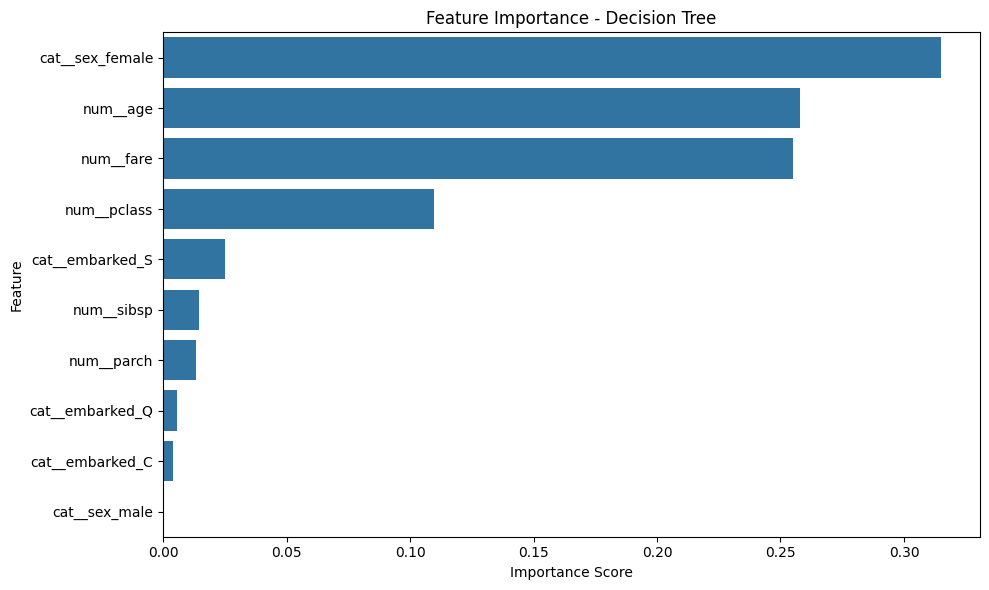

In [136]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Final Conclusion

Three classification models were developed and evaluated to predict Titanic passenger survival.

- Logistic Regression achieved the highest ROC-AUC score of 0.8437.
- Decision Tree achieved the highest F1-score of 0.7556 among the original models.
- Random Forest achieved the highest precision of 0.8000.
- GridSearchCV was used to tune the Decision Tree across 45 hyperparameter combinations using 5-fold cross-validation.
- The tuned Decision Tree achieved a lower test F1-score than the original model. Therefore, the original Decision Tree was retained based on test F1-score.
- Feature importance analysis identified sex, age, fare, and passenger class as influential features in the original Decision Tree.

This project demonstrates data preprocessing, classification, model evaluation, hyperparameter tuning, and model interpretation using Scikit-learn.